# P12 · Mobile-Money Fraud Miner — Data Lead Notebook (Weeks 6 and 7)

**Course:** DS-311 Data Mining · BS-AI 2024F, Section A · NBC, NUST · Fall 2026  
**Group 2:** Shoaib Malik (Team Leader), Uzair Kakar, Salman Hussian  
**Scope of this notebook:** the *Data lead* work of the first two project weeks: **M0 (Week 6)** acquire the data, and **M1 (Week 7)** data-quality report and exploratory data analysis (EDA).

---
### How to read this notebook (for the instructor)
Every section follows the same pattern, so it is easy to see *what was done, where, and why*:

| Label | Meaning |
|---|---|
| **Purpose** | Which project question or pipeline stage this section serves |
| **What we did** | The steps, in plain words |
| **How to read the output** | What the table or chart under the code shows |
| **Finding** | A line printed by the code itself with the real numbers (nothing typed by hand) |

### Notebook map

| Section | Week | Pipeline stage (course guide) | Question it answers |
|---|---|---|---|
| 0. Setup | 6 | Reproducibility | Are seeds, versions and settings fixed? |
| 1. Acquire and describe the data | 6 (M0) | Stage 1: Acquire and integrate | Where does the data come from, how big is it, what does each column mean? |
| 2. Data-quality report | 7 (M1) | Stage 2: Data-quality report | Is the data clean and consistent, and what did we decide about each problem? |
| 3. Exploratory data analysis | 7 (M1) | Stage 3: Explore (with hypothesis tests) | Where does fraud occur, and why is accuracy meaningless at 0.1% fraud? |
| 4. Save outputs and hand-off | 7 | Team workflow | What do teammates and the dashboard receive from this notebook? |
| 5. Summary and next steps | 7 | Interpretation | What did we learn, and what comes in Week 8? |

**How to run:** Runtime > Run all. The first data cell asks for Google Drive access (click Allow). Full run on the whole dataset takes a few minutes.

## 0. Setup

**Purpose:** make the notebook reproducible (a course requirement): the same code gives the same results for anyone who runs it.

**What we did:** imported the libraries, fixed the random seed (`SEED = 42`), set display options and printed the library versions. `DEV_SAMPLE` is a switch for quick practice runs on a smaller random subset; **it must stay `None` for the final results.**

In [50]:
import os, sys, glob, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

DEV_SAMPLE = None      # e.g. 500_000 for a quick dry run. Keep None for the final run.

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("Seed:", SEED, "| DEV_SAMPLE:", DEV_SAMPLE)

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | scipy 1.16.3 | scikit-learn 1.6.1
Seed: 42 | DEV_SAMPLE: None


## 1. Acquire and describe the data (Week 6, M0)

### 1.1 Load PaySim

**Purpose:** Stage 1 of the pipeline: load the original data inside Colab and confirm its size.

**What we did:**
- The dataset is **PaySim**, a synthetic mobile-money transaction dataset (Kaggle: `ealaxi/paysim1`) simulated from real mobile-money logs. It contains no personal data.
- We keep one copy in a shared Google Drive folder (`DS311_P12_Data/raw`) so all three members read the *same file*. The notebook mounts Drive and copies the CSV to Colab's local disk (faster than reading from Drive repeatedly).
- **Fallback:** if the Drive copy is missing, the notebook downloads the file directly from Kaggle. This keeps the notebook reproducible from the original source, as the course requires.

**How to read the output:** the printed line tells which source was used, and the shape is (rows, columns).

In [51]:
# ---- CELL:LOAD ----
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/DS311_P12_Data"   # shared team folder
RAW_DIR    = DRIVE_ROOT + "/raw"                        # original CSV (never edited)
OUT_DIR    = DRIVE_ROOT + "/processed"                  # files created by the team
LOCAL      = "/content/paysim.csv"

src = glob.glob(RAW_DIR + "/*.csv")
if src:
    DATA_SOURCE = "Team Google Drive copy (raw/)"
    if not os.path.exists(LOCAL):
        shutil.copy(src[0], LOCAL)
else:
    DATA_SOURCE = "Direct download from Kaggle (ealaxi/paysim1)"
    !pip install -q kagglehub
    import kagglehub
    LOCAL = glob.glob(kagglehub.dataset_download("ealaxi/paysim1") + "/*.csv")[0]

df = pd.read_csv(LOCAL)
if DEV_SAMPLE:
    df = df.sample(DEV_SAMPLE, random_state=SEED).reset_index(drop=True)

print("Loaded from:", DATA_SOURCE)
print("Shape (rows, columns):", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded from: Team Google Drive copy (raw/)
Shape (rows, columns): (6362620, 11)


### 1.2 First look: size, data types, example rows, fraud count

**Purpose:** confirm the basics we quote in the proposal (size, number of frauds) and check that each column was read with a sensible type.

**What we did:** printed the number of rows and columns, memory use, each column's data type, the first rows, and the number and share of fraudulent transactions (`isFraud = 1`). We also converted `type` to a *category* column: it has only five values, so this saves memory.

**How to read the output:** `object` means text (the account names); `float64` means decimal numbers; `int64` means whole numbers. In the first rows, a fraud row (`isFraud = 1`) is typically a TRANSFER that empties the sender's balance, followed by a CASH_OUT of the same amount.

In [52]:
df["type"] = df["type"].astype("category")

n_rows, n_cols = df.shape
n_fraud = int(df["isFraud"].sum())
fraud_rate = df["isFraud"].mean()

print(f"Rows: {n_rows:,} | Columns: {n_cols}")
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
display(df.dtypes.to_frame("data type"))
display(df.head())
print(f"Finding: {n_fraud:,} of {n_rows:,} transactions are fraud = {fraud_rate:.4%} (about 1 in {round(1/fraud_rate):,}).")

Rows: 6,362,620 | Columns: 11
Memory used: 1.17 GB


,data type
step,int64
type,category
amount,float64
nameOrig,object
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,object
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


Finding: 8,213 of 6,362,620 transactions are fraud = 0.1291% (about 1 in 775).


### 1.3 Data dictionary

**Purpose:** a short data dictionary is a required deliverable at M0. It tells every teammate (and the instructor) what each column means and which ones need care.

**What we did:** wrote one line per column: meaning, data type found, an example value, and a note on how we will use it. The "Watch out" notes anticipate the **leakage** issues we will test in Week 8.

**How to read the output:** the last column is our plan for the column, not a result.

In [53]:
dictionary = pd.DataFrame([
    ("step",           "Time unit: 1 step = 1 hour of the simulation",                      "Used to build hour and day features; basis for the time-based split"),
    ("type",           "Transaction type: CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER",      "Key categorical feature; fraud is checked per type"),
    ("amount",         "Transaction amount (local currency units)",                           "Very skewed; log scale used for plots"),
    ("nameOrig",       "ID of the customer who starts the transaction",                       "Identifier only; NOT used as a raw feature"),
    ("oldbalanceOrg",  "Sender balance before the transaction",                               "Used for balance-consistency checks and features"),
    ("newbalanceOrig", "Sender balance after the transaction",                                "Watch out: post-transaction value, possible leakage (tested in Week 8)"),
    ("nameDest",       "ID of the recipient (names starting with M are merchants)",           "Identifier only; NOT used as a raw feature"),
    ("oldbalanceDest", "Recipient balance before the transaction",                            "Not tracked for merchants"),
    ("newbalanceDest", "Recipient balance after the transaction",                             "Watch out: post-transaction value, possible leakage"),
    ("isFraud",        "TARGET label: 1 = fraudulent transaction, 0 = normal",                "What we predict"),
    ("isFlaggedFraud", "Flag raised by the simulator's own business rule",                    "Watch out: a rule output; checked in 3.8 and NOT used as a feature"),
], columns=["Column", "Meaning", "Plan / watch out"])

dictionary["Data type found"] = dictionary["Column"].map(lambda c: str(df[c].dtype))
dictionary["Example (first row)"] = dictionary["Column"].map(lambda c: str(df[c].iloc[0]))
display(dictionary[["Column", "Meaning", "Data type found", "Example (first row)", "Plan / watch out"]])

,Column,Meaning,Data type found,Example (first row),Plan / watch out
0,step,Time unit: 1 step = 1 hour of the simulation,int64,1,Used to build hour and day features; basis for the time-based split
1,type,"Transaction type: CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER",category,PAYMENT,Key categorical feature; fraud is checked per type
2,amount,Transaction amount (local currency units),float64,9839.64,Very skewed; log scale used for plots
3,nameOrig,ID of the customer who starts the transaction,object,C1231006815,Identifier only; NOT used as a raw feature
4,oldbalanceOrg,Sender balance before the transaction,float64,170136.0,Used for balance-consistency checks and features
5,newbalanceOrig,Sender balance after the transaction,float64,160296.36,"Watch out: post-transaction value, possible leakage (tested in Week 8)"
6,nameDest,ID of the recipient (names starting with M are merchants),object,M1979787155,Identifier only; NOT used as a raw feature
7,oldbalanceDest,Recipient balance before the transaction,float64,0.0,Not tracked for merchants
8,newbalanceDest,Recipient balance after the transaction,float64,0.0,"Watch out: post-transaction value, possible leakage"
9,isFraud,"TARGET label: 1 = fraudulent transaction, 0 = normal",int64,0,What we predict


## 2. Data-quality report (Week 7, M1)

**Purpose:** Stage 2 of the pipeline. Before any modelling we must know whether the data has missing values, duplicates, impossible values, inconsistencies or outliers, and we must **justify what we do about each one**.

**What we did:** ran six groups of checks (2.1 to 2.6). Every check adds one row to a single **Data-quality summary table** at the end of this section, with three columns: the check, what we found (counted by the code), and our decision.

**Decision policy we follow:**
- *Remove* a record only if it is clearly an error (for example an exact duplicate).
- *Keep and engineer* unusual-but-possible values: in fraud detection the odd records are often the fraud, so deleting them would hide what we want to find.
- *Report honestly* anything that limits the conclusions.

### 2.1 Missing values and duplicate rows

**What we did:** counted empty cells in every column and exact duplicate rows (identical in all columns). If duplicates exist, they are removed (first copy kept).

**How to read the output:** the table shows missing cells per column; zeros mean nothing is missing.

In [54]:
dq = []   # data-quality log: one row per check
def add_dq(check, found, decision):
    dq.append({"Check": check, "What we found": found, "Decision": decision})

miss = df.isnull().sum()
display(miss.to_frame("missing cells").T)
total_missing = int(miss.sum())

n_dup = int(df.duplicated().sum())
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)

add_dq("Missing values", f"{total_missing:,} missing cells in total",
       "No imputation needed" if total_missing == 0 else "Columns above need review; impute or drop with justification")
add_dq("Exact duplicate rows", f"{n_dup:,} duplicate rows",
       "None to remove" if n_dup == 0 else "Removed exact duplicates (first copy kept)")
print(f"Finding: {total_missing:,} missing cells and {n_dup:,} exact duplicate rows.")

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
missing cells,0,0,0,0,0,0,0,0,0,0,0


Finding: 0 missing cells and 0 exact duplicate rows.


### 2.2 Validity: allowed categories and impossible values

**What we did:** checked that `type` only contains the five documented values, that amounts and balances are never negative, how many transactions have amount 0, that `step` covers a sensible range, and that the flag columns only contain 0 or 1.

**How to read the output:** every count should be 0 if the data is valid. Any non-zero count is listed in the summary table with a decision.

In [55]:
valid_types = {"CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"}
bad_types = set(df["type"].unique()) - valid_types

num_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
neg = {c: int((df[c] < 0).sum()) for c in num_cols}
zero_amt = int((df["amount"] == 0).sum())
step_min, step_max = int(df["step"].min()), int(df["step"].max())
bad_flags = int((~df["isFraud"].isin([0, 1])).sum() + (~df["isFlaggedFraud"].isin([0, 1])).sum())

print("Unexpected transaction types:", bad_types if bad_types else "none")
print("Negative values per column:", neg)
print("Transactions with amount = 0:", f"{zero_amt:,}")
print(f"step range: {step_min} to {step_max} (hours; about {step_max/24:.0f} days)")
print("Invalid values in isFraud / isFlaggedFraud:", bad_flags)

add_dq("Allowed transaction types", f"{len(bad_types)} unexpected types", "None to fix" if not bad_types else "Investigate and correct")
add_dq("Negative amounts or balances", f"{sum(neg.values()):,} negative values", "None to fix" if sum(neg.values()) == 0 else "Investigate; remove if clearly erroneous")
zero = df[df["amount"] == 0]
zero_fraud = int(zero["isFraud"].sum())
zero_types = zero["type"].value_counts()
zero_types = zero_types[zero_types > 0].to_dict()
add_dq("Amount equal to 0",
       f"{zero_amt:,} rows; {zero_fraud} are fraud; types: {zero_types}",
       "Kept: every one is fraud, so removing them would delete signal" if zero_fraud == zero_amt
       else "Kept; mixed labels, flagged for the feature stage")
add_dq("Time range (step)", f"{step_min} to {step_max} hourly steps", "Valid range; used for hour/day features and the time-based split")
add_dq("Label and flag values", f"{bad_flags:,} invalid values", "None to fix" if bad_flags == 0 else "Investigate")

Unexpected transaction types: none
Negative values per column: {'amount': 0, 'oldbalanceOrg': 0, 'newbalanceOrig': 0, 'oldbalanceDest': 0, 'newbalanceDest': 0}
Transactions with amount = 0: 16
step range: 1 to 743 (hours; about 31 days)
Invalid values in isFraud / isFlaggedFraud: 0


### 2.3 Consistency: do the balances add up?

**What we did:** for each transaction we computed what the sender's new balance *should* be: `old - amount` for most types, and `old + amount` for CASH_IN. We then counted rows where the recorded `newbalanceOrig` differs from that by more than 0.01. We also counted rows where the sender's balance was 0 before the transaction although a positive amount was sent, and transfers or cash-outs whose recipient balance was already 0.

**Why it matters:** inconsistent balances can be data errors, but in fraud data they can also be a *signal*. We therefore **count and keep** them, and turn them into "balance-error" features in Week 8 instead of deleting them.

**How to read the output:** the share column shows what fraction of each transaction type is inconsistent.

In [56]:
is_cash_in = (df["type"] == "CASH_IN").to_numpy()
expected_new_orig = np.where(is_cash_in,
                             df["oldbalanceOrg"].to_numpy() + df["amount"].to_numpy(),
                             df["oldbalanceOrg"].to_numpy() - df["amount"].to_numpy())
orig_mismatch = np.abs(expected_new_orig - df["newbalanceOrig"].to_numpy()) > 0.01

mm = (pd.Series(orig_mismatch, index=df.index)
        .groupby(df["type"], observed=True).agg(["sum", "mean"])
        .rename(columns={"sum": "inconsistent rows", "mean": "share of type"}))
display(mm)

zero_orig_amt = ((df["oldbalanceOrg"] == 0) & (df["amount"] > 0))
zo = zero_orig_amt.groupby(df["type"], observed=True).agg(["sum", "mean"]).rename(columns={"sum": "rows", "mean": "share of type"})
print("Sender balance was 0 before sending a positive amount:")
display(zo)

tc = df["type"].isin(["TRANSFER", "CASH_OUT"])
dest_zero = int((df.loc[tc, "oldbalanceDest"] == 0).sum())

add_dq("Sender balance does not add up", f"{int(orig_mismatch.sum()):,} rows ({orig_mismatch.mean():.2%} of all)",
       "Kept (not errors to delete). Converted into balance-error features in Week 8; effect tested by ablation")
add_dq("Sender balance 0 before a positive amount", f"{int(zero_orig_amt.sum()):,} rows",
       "Kept and flagged; possible signal and possible simulator artefact")
add_dq("Recipient balance 0 before TRANSFER/CASH_OUT", f"{dest_zero:,} rows ({dest_zero / tc.sum():.2%} of those types)",
       "Kept; becomes the 'destination was empty' feature")
print(f"Finding: {orig_mismatch.mean():.2%} of all rows have a sender balance that does not add up.")

,inconsistent rows,share of type
type,,
CASH_IN,101096,0.0722
CASH_OUT,1991269,0.8900
DEBIT,12462,0.3008
PAYMENT,1165894,0.5419
TRANSFER,508782,0.9547


Sender balance was 0 before sending a positive amount:


,rows,share of type
type,,
CASH_IN,13464,0.0096
CASH_OUT,1025783,0.4585
DEBIT,6158,0.1486
PAYMENT,774245,0.3599
TRANSFER,282783,0.5306


Finding: 59.40% of all rows have a sender balance that does not add up.


### 2.4 Identifiers: account IDs and merchants

**What we did:** counted how many distinct sender and recipient accounts exist, how often an account appears more than once, and the share of transactions sent to merchants (IDs that start with `M`).

**Why it matters:** account-level (velocity) features only make sense if accounts repeat. If most accounts appear once, per-account history is very limited, and we must say so honestly in the report.

**How to read the output:** "appear only once" is the share of accounts that have a single transaction.

In [57]:
orig_counts = df["nameOrig"].value_counts()
dest_counts = df["nameDest"].value_counts()
merchant_share = (df["nameDest"].str[0] == "M").mean()

print(f"Distinct sender accounts   : {len(orig_counts):,} | appear only once: {(orig_counts == 1).mean():.2%} | max transactions by one account: {int(orig_counts.max())}")
print(f"Distinct recipient accounts: {len(dest_counts):,} | appear only once: {(dest_counts == 1).mean():.2%} | max transactions to one account: {int(dest_counts.max())}")
print(f"Share of transactions sent to merchants (ID starts with M): {merchant_share:.2%}")

add_dq("Account IDs repeat?", f"{(orig_counts == 1).mean():.1%} of senders and {(dest_counts == 1).mean():.1%} of recipients appear once",
       "IDs are not used as raw features. Account history features (expert module) only if repeats justify them")
del orig_counts, dest_counts

Distinct sender accounts   : 6,353,307 | appear only once: 99.85% | max transactions by one account: 3
Distinct recipient accounts: 2,722,362 | appear only once: 83.12% | max transactions to one account: 113
Share of transactions sent to merchants (ID starts with M): 33.81%


### 2.5 Outliers in the amount

**What we did:** looked at the percentiles of `amount`, counted outliers with the standard **IQR rule** (above Q3 + 1.5 x IQR) for each transaction type, and plotted the amounts on a log scale.

**Why we keep them:** very large transfers are real in mobile money and are exactly where fraud may hide. Deleting them would remove the signal. We use the log scale for plots and a robust or tree-based model later.

**How to read the output:** the histogram uses log10 of the amount; a long right tail means a few very large transactions.

Amount percentiles:


,amount
median,"74,871.9400"
90th pct,"365,423.3090"
99th pct,"1,615,979.4716"
99.9th pct,"8,956,797.6770"


Maximum amount: 92,445,516.64


,IQR outliers,share of type
type,,
CASH_IN,27829,0.0199
CASH_OUT,49220,0.0220
DEBIT,3038,0.0733
PAYMENT,111703,0.0519
TRANSFER,39793,0.0747


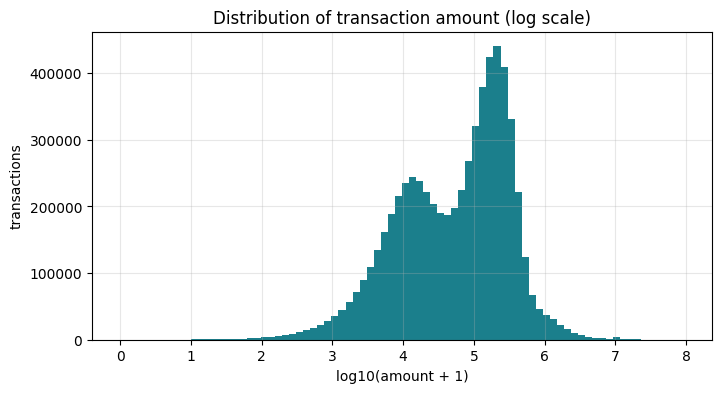

In [58]:
pcts = df["amount"].quantile([0.5, 0.9, 0.99, 0.999]).rename({0.5: "median", 0.9: "90th pct", 0.99: "99th pct", 0.999: "99.9th pct"})
print("Amount percentiles:"); display(pcts.to_frame("amount"))
print("Maximum amount:", f"{df['amount'].max():,.2f}")

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); return (s > q3 + 1.5 * (q3 - q1)).sum()
out_by_type = df.groupby("type", observed=True)["amount"].apply(iqr_outliers).to_frame("IQR outliers")
out_by_type["share of type"] = out_by_type["IQR outliers"] / df["type"].value_counts()
display(out_by_type)

fig, ax = plt.subplots()
ax.hist(np.log10(df["amount"] + 1), bins=80, color="#1B7F8C")
ax.set_xlabel("log10(amount + 1)"); ax.set_ylabel("transactions"); ax.set_title("Distribution of transaction amount (log scale)")
plt.show()

add_dq("Outliers in amount (IQR rule)", f"{int(out_by_type['IQR outliers'].sum()):,} rows above the IQR fence; maximum {df['amount'].max():,.0f}",
       "Kept: large amounts are legitimate and may carry fraud. Log scale for plots; scaling or robust models in Week 8")

### 2.6 Data-quality summary table

**Purpose:** one place where the instructor can see every check, the result found by the code, and our decision.

In [59]:
dq_table = pd.DataFrame(dq)
dq_table.index = dq_table.index + 1
display(dq_table)

,Check,What we found,Decision
1,Missing values,0 missing cells in total,No imputation needed
2,Exact duplicate rows,0 duplicate rows,None to remove
3,Allowed transaction types,0 unexpected types,None to fix
4,Negative amounts or balances,0 negative values,None to fix
5,Amount equal to 0,16 rows; 16 are fraud; types: {'CASH_OUT': 16},"Kept: every one is fraud, so removing them would delete signal"
6,Time range (step),1 to 743 hourly steps,Valid range; used for hour/day features and the time-based split
7,Label and flag values,0 invalid values,None to fix
8,Sender balance does not add up,"3,779,503 rows (59.40% of all)",Kept (not errors to delete). Converted into balance-error features in Week 8; effect tested by ablation
9,Sender balance 0 before a positive amount,"2,102,433 rows",Kept and flagged; possible signal and possible simulator artefact
10,Recipient balance 0 before TRANSFER/CASH_OUT,"389,320 rows (14.05% of those types)",Kept; becomes the 'destination was empty' feature


## 3. Exploratory data analysis (Week 7, M1)

**Purpose:** Stage 3 of the pipeline, and the first project question: *where does fraud occur, and why is accuracy meaningless at 0.1% fraud?*

**What we did:** eight short analyses (3.1 to 3.8): class balance and the accuracy trap, fraud by transaction type, fraud over time, amounts, balance patterns, correlations, two hypothesis tests, and a first look at the `isFlaggedFraud` column.

### 3.1 Class imbalance and the accuracy trap

**What we did:** counted normal and fraudulent transactions, then built the *laziest possible model*: a dummy classifier that always answers "not fraud". We measured its accuracy, its recall (share of frauds caught) and its precision.

**Why it matters:** this shows why **accuracy cannot be used** in this project. The next sections of the project use PR-AUC and recall at fixed precision instead.

**How to read the output:** compare the accuracy (very high) with the recall (zero).

,transactions,share
Normal (0),6354407,0.9987
Fraud (1),8213,0.0013


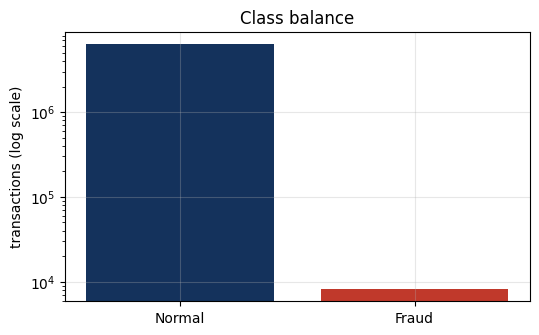

Finding: a model that ALWAYS says 'not fraud' is 99.87% accurate, but its recall is 0% and it catches 0 of 8,213 frauds.


In [60]:
class_counts = df["isFraud"].value_counts().sort_index()
display(pd.DataFrame({"transactions": class_counts.values, "share": class_counts.values / len(df)},
                     index=["Normal (0)", "Fraud (1)"]))

dummy = DummyClassifier(strategy="most_frequent").fit(df[["amount"]], df["isFraud"])
pred = dummy.predict(df[["amount"]])
acc = accuracy_score(df["isFraud"], pred)
rec = recall_score(df["isFraud"], pred, zero_division=0)
prec = precision_score(df["isFraud"], pred, zero_division=0)
caught = int(((pred == 1) & (df["isFraud"] == 1)).sum())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Normal", "Fraud"], class_counts.values, color=["#14325C", "#C0392B"])
ax.set_yscale("log"); ax.set_ylabel("transactions (log scale)"); ax.set_title("Class balance")
plt.show()

print(f"Finding: a model that ALWAYS says 'not fraud' is {acc:.2%} accurate, but its recall is {rec:.0%} and it catches {caught} of {int(df['isFraud'].sum()):,} frauds.")

### 3.2 Where does fraud occur? Fraud by transaction type

**What we did:** for each transaction type we counted the transactions, the frauds and the fraud rate.

**How to read the output:** `fraud_rate` is the share of that type that is fraudulent. The charts show the volume of each type next to the number of frauds, so you can see where fraud is concentrated.

,transactions,frauds,fraud_rate,share_of_all_frauds
type,,,,
CASH_IN,1399284,0,0.0000,0.0000
CASH_OUT,2237500,4116,0.0018,0.5012
DEBIT,41432,0,0.0000,0.0000
PAYMENT,2151495,0,0.0000,0.0000
TRANSFER,532909,4097,0.0077,0.4988


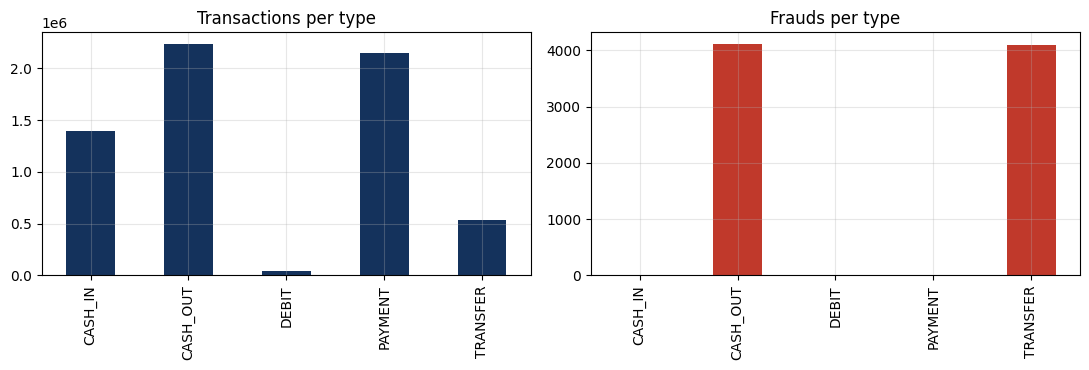

Finding: fraud occurs only in ['CASH_OUT', 'TRANSFER']. All other types have 0 frauds.


In [61]:
by_type = (df.groupby("type", observed=True)["isFraud"]
             .agg(transactions="count", frauds="sum", fraud_rate="mean"))
by_type["share_of_all_frauds"] = by_type["frauds"] / by_type["frauds"].sum()
display(by_type)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_type["transactions"].plot.bar(ax=axes[0], color="#14325C"); axes[0].set_title("Transactions per type"); axes[0].set_xlabel("")
by_type["frauds"].plot.bar(ax=axes[1], color="#C0392B");       axes[1].set_title("Frauds per type");       axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

types_with_fraud = list(by_type.index[by_type["frauds"] > 0])
print(f"Finding: fraud occurs only in {types_with_fraud}. All other types have 0 frauds.")

### 3.3 Fraud over time

**What we did:** created two time features from `step`: **hour of day** (`(step-1) mod 24`) and **day** (`(step-1) // 24 + 1`). We then plotted frauds per day and the fraud rate by hour of day.

**Note:** this is a simulated clock, so we make no claims about real weekdays or clock times. Fraud counts are spread over all hours, but normal volume drops sharply at night, so the fraud rate is far higher in quiet hours. Hour is informative, but it is a simulator pattern and may not transfer to real wallets. This also matters for the time-based train/test split in Week 8.

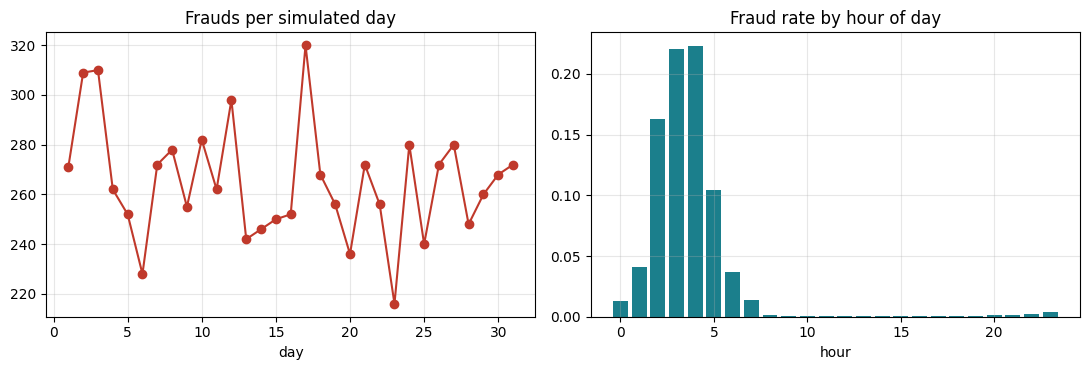

Finding: frauds per day range from 216 to 320 (mean 265); fraud rate by hour ranges from 0.053% to 22.303%.
Normal transactions per hour range from 1,241 to 647,814.


In [62]:
df["hour"] = ((df["step"] - 1) % 24).astype("int8")
df["day"]  = ((df["step"] - 1) // 24 + 1).astype("int16")

by_day  = df.groupby("day")["isFraud"].agg(transactions="count", frauds="sum", fraud_rate="mean")
by_hour = df.groupby("hour")["isFraud"].agg(transactions="count", frauds="sum", fraud_rate="mean")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(by_day.index, by_day["frauds"], marker="o", color="#C0392B"); axes[0].set_title("Frauds per simulated day"); axes[0].set_xlabel("day")
axes[1].bar(by_hour.index, by_hour["fraud_rate"], color="#1B7F8C"); axes[1].set_title("Fraud rate by hour of day"); axes[1].set_xlabel("hour")
plt.tight_layout(); plt.show()

print(f"Finding: frauds per day range from {int(by_day['frauds'].min())} to {int(by_day['frauds'].max())} (mean {by_day['frauds'].mean():.0f}); "
      f"fraud rate by hour ranges from {by_hour['fraud_rate'].min():.3%} to {by_hour['fraud_rate'].max():.3%}.")
print(f"Normal transactions per hour range from {int(by_hour['transactions'].min()):,} to {int(by_hour['transactions'].max()):,}.")

### 3.4 Do fraudulent transactions have different amounts?

**What we did:** because fraud only happens in TRANSFER and CASH_OUT, we compared the amounts of fraud and normal transactions **inside those two types** (we call this subset `sub`). We show summary statistics and overlay the two distributions on a log scale.

**How to read the output:** compare the median and the 90th percentile of the two groups in the table; in the chart, the fraud distribution being shifted to the right means larger amounts.

Subset TRANSFER + CASH_OUT: 2,770,409 rows (43.5% of all rows) containing 8,213 of 8,213 frauds.


,count,mean,std,min,50%,90%,99%,max
isFraud,,,,,,,,
Normal,"2,762,196.0000","314,115.4962","877,144.1496",0.0100,"171,034.4600","540,837.9200","2,580,263.9160","92,445,516.6400"
Fraud,"8,213.0000","1,467,967.2991","2,404,252.9472",0.0000,"441,423.4400","4,521,723.5120","10,000,000.0000","10,000,000.0000"


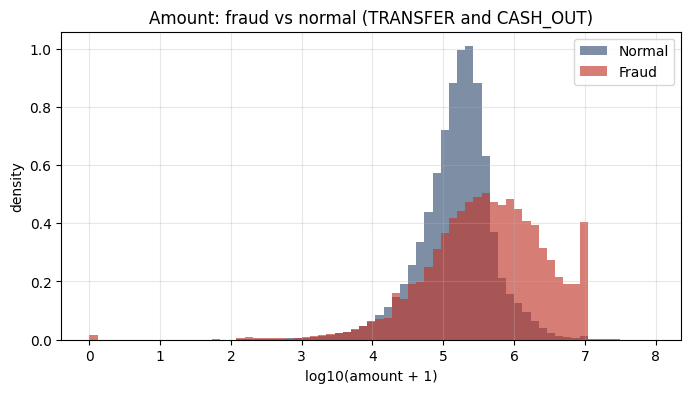

Finding: median fraud amount 441,423 vs median normal amount 171,034.


In [63]:
sub = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
print(f"Subset TRANSFER + CASH_OUT: {len(sub):,} rows ({len(sub)/len(df):.1%} of all rows) containing {int(sub['isFraud'].sum()):,} of {int(df['isFraud'].sum()):,} frauds.")

display(sub.groupby("isFraud")["amount"].describe(percentiles=[0.5, 0.9, 0.99]).rename(index={0: "Normal", 1: "Fraud"}))

fig, ax = plt.subplots()
bins = np.linspace(0, np.log10(sub["amount"].max() + 1), 70)
ax.hist(np.log10(sub.loc[sub["isFraud"] == 0, "amount"] + 1), bins=bins, density=True, alpha=0.55, label="Normal", color="#14325C")
ax.hist(np.log10(sub.loc[sub["isFraud"] == 1, "amount"] + 1), bins=bins, density=True, alpha=0.65, label="Fraud",  color="#C0392B")
ax.set_xlabel("log10(amount + 1)"); ax.set_ylabel("density"); ax.set_title("Amount: fraud vs normal (TRANSFER and CASH_OUT)"); ax.legend()
plt.show()
med_f = sub.loc[sub["isFraud"] == 1, "amount"].median(); med_n = sub.loc[sub["isFraud"] == 0, "amount"].median()
print(f"Finding: median fraud amount {med_f:,.0f} vs median normal amount {med_n:,.0f}.")

### 3.5 The behaviour pattern of fraud: balances

**What we did:** inside `sub`, we compared fraud and normal transactions on three simple patterns: (1) the sender's account is **emptied** (balance was positive, becomes 0), (2) the **amount equals the whole balance**, (3) the **recipient's balance was 0** before the transaction.

**Why it matters:** these patterns are the basis of the interpretable anomaly flags and balance features we will build in Week 8. They are also the reason we must run a leakage check: very strong patterns can make a model look unrealistically good.

**How to read the output:** each cell is the share of that group (Normal or Fraud) showing the pattern.

,sender account emptied,amount equals sender balance,recipient balance was 0
isFraud,,,
Normal,0.4272,0.0000,0.1390
Fraud,0.9755,0.9763,0.6515


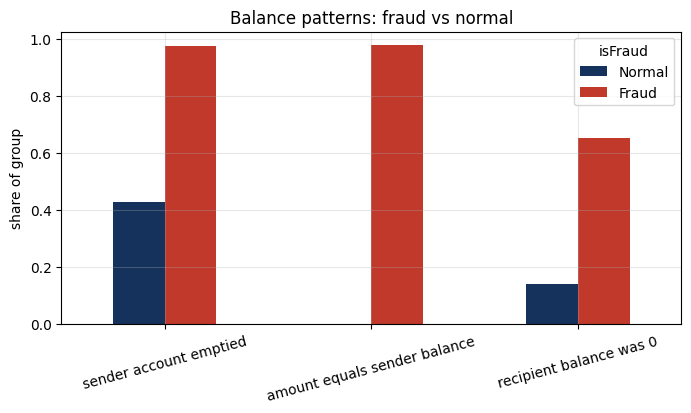

Finding: 97.6% of frauds empty the sender's account, versus 42.7% of normal transactions.


In [64]:
patterns = pd.DataFrame({
    "sender account emptied":       (sub["oldbalanceOrg"] > 0) & (sub["newbalanceOrig"] == 0),
    "amount equals sender balance": np.isclose(sub["amount"], sub["oldbalanceOrg"]) & (sub["oldbalanceOrg"] > 0),
    "recipient balance was 0":      sub["oldbalanceDest"] == 0,
})
pat = patterns.groupby(sub["isFraud"]).mean().rename(index={0: "Normal", 1: "Fraud"})
display(pat)

pat.T.plot.bar(figsize=(8, 3.8), color=["#14325C", "#C0392B"]); plt.ylabel("share of group"); plt.xticks(rotation=15)
plt.title("Balance patterns: fraud vs normal"); plt.show()
print(f"Finding: {pat.loc['Fraud', 'sender account emptied']:.1%} of frauds empty the sender's account, versus {pat.loc['Normal', 'sender account emptied']:.1%} of normal transactions.")

### 3.6 Correlations

**What we did:** computed the correlation between the numeric columns on a random sample of 500,000 rows (a full calculation is not needed and uses more memory) and drew a heatmap.

**How to read the output:** values near +1 or -1 mean a strong linear relationship. The balance columns are strongly related to each other (before/after balances). The last row/column shows how each column relates to `isFraud`; since fraud is rare, correlations with it are small, which is another reason we use models and not simple correlations.

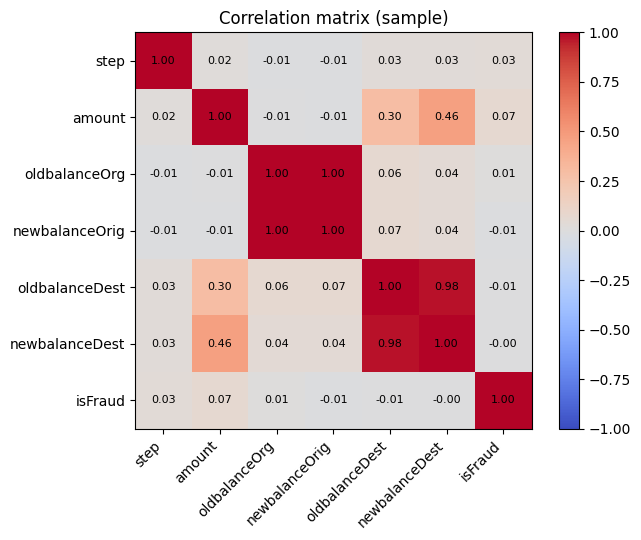

Correlation of each column with isFraud:


,correlation
step,0.0325
amount,0.0690
oldbalanceOrg,0.0072
newbalanceOrig,-0.0096
oldbalanceDest,-0.0065
newbalanceDest,-0.0007


In [65]:
num = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
smp = df[num].sample(min(500_000, len(df)), random_state=SEED)
corr = smp.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im); ax.set_title("Correlation matrix (sample)"); plt.tight_layout(); plt.show()
print("Correlation of each column with isFraud:"); display(corr["isFraud"].drop("isFraud").to_frame("correlation"))

### 3.7 Hypothesis tests

**Purpose:** the course requires at least one hypothesis test. We run two, at significance level alpha = 0.05.

**Test 1: Is fraud related to transaction type? (chi-square test of independence)**  
H0: fraud and transaction type are independent. H1: they are related. We also report **Cramer's V** (0 = no association, 1 = perfect association) because with millions of rows the p-value is tiny for almost anything, so the *size* of the effect matters more.

**Test 2: Do fraudulent transactions have different amounts? (Mann-Whitney U test)**  
H0: fraud and normal amounts come from the same distribution. H1: they differ. This test does not assume a normal distribution, which suits skewed amounts. We compare all frauds against a random sample of 200,000 normal transactions in TRANSFER and CASH_OUT, and report the **common-language effect size**: the probability that a randomly chosen fraud amount is larger than a randomly chosen normal amount (0.5 means no difference).

In [66]:
p_show = lambda p: "< 1e-300" if p == 0 else f"{p:.3e}"
# ---- Test 1: chi-square, fraud vs type ----
ct = pd.crosstab(df["type"], df["isFraud"])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
print("Test 1: chi-square test (fraud vs transaction type)")
print(f"  chi2 = {chi2:,.1f}, degrees of freedom = {dof}, p-value = {p_show(p_chi)}, Cramer's V = {cramers_v:.3f}")
print("  Decision:", "reject H0 (fraud depends on type)" if p_chi < 0.05 else "fail to reject H0")

# ---- Test 2: Mann-Whitney U, amount of fraud vs normal ----
fraud_amt  = sub.loc[sub["isFraud"] == 1, "amount"].to_numpy()
normal_amt = sub.loc[sub["isFraud"] == 0, "amount"].sample(min(200_000, int((sub["isFraud"] == 0).sum())), random_state=SEED).to_numpy()
U, p_mw = stats.mannwhitneyu(fraud_amt, normal_amt, alternative="two-sided")
cles = U / (len(fraud_amt) * len(normal_amt))
print("\nTest 2: Mann-Whitney U test (amount: fraud vs normal, TRANSFER and CASH_OUT)")
print(f"  U = {U:,.0f}, p-value = {p_show(p_mw)}, P(fraud amount > normal amount) = {cles:.3f}")
print("  Decision:", "reject H0 (amounts differ)" if p_mw < 0.05 else "fail to reject H0")

Test 1: chi-square test (fraud vs transaction type)
  chi2 = 22,082.5, degrees of freedom = 4, p-value = < 1e-300, Cramer's V = 0.059
  Decision: reject H0 (fraud depends on type)

Test 2: Mann-Whitney U test (amount: fraud vs normal, TRANSFER and CASH_OUT)
  U = 1,122,594,512, p-value = < 1e-300, P(fraud amount > normal amount) = 0.683
  Decision: reject H0 (amounts differ)


### 3.8 First look at `isFlaggedFraud` (preview of the Week 8 leakage check)

**What we did:** compared the simulator's own flag with the true label: how many rows are flagged, how many of those are really fraud, and what share of all frauds the flag catches.

**Why it matters:** this column comes from a fixed business rule, not from a customer behaviour. Using it as a model input would be circular, so we exclude it from the features. The full leakage analysis comes in Week 8.

**How to read the output:** rows are the flag (0/1), columns are the true label.

In [67]:
flag_ct = pd.crosstab(df["isFlaggedFraud"], df["isFraud"], rownames=["isFlaggedFraud"], colnames=["isFraud"])
display(flag_ct)
n_flagged = int(df["isFlaggedFraud"].sum())
flag_recall = int(((df["isFlaggedFraud"] == 1) & (df["isFraud"] == 1)).sum()) / max(int(df["isFraud"].sum()), 1)
print(f"Finding: the rule flags only {n_flagged:,} transactions and catches {flag_recall:.2%} of all frauds, so it is not a useful detector and is excluded from the features.")

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


Finding: the rule flags only 16 transactions and catches 0.19% of all frauds, so it is not a useful detector and is excluded from the features.


## 4. Save outputs and hand-off to the team (Week 7)

**Purpose:** teammates should not repeat our work. We save small, ready-to-use files in the shared Drive folder `DS311_P12_Data/processed/`.

**What we did:**
- Saved three **summary tables** (fraud by type, by day, by hour). Salman uses them for the dashboard EDA page without loading 6 million rows.
- Saved the **TRANSFER + CASH_OUT subset** with the new `hour` and `day` columns (the file the models will use in Week 8). Stored as Parquet (smaller and faster); if Parquet is not available, a compressed CSV is saved instead.
- The original file in `raw/` is never changed.

In [68]:
os.makedirs(OUT_DIR, exist_ok=True)

by_type.to_csv(OUT_DIR + "/fraud_by_type.csv")
by_day.to_csv(OUT_DIR + "/fraud_by_day.csv")
by_hour.to_csv(OUT_DIR + "/fraud_by_hour.csv")
dq_table.to_csv(OUT_DIR + "/data_quality_summary.csv", index_label="#")

try:
    path = OUT_DIR + "/paysim_transfer_cashout.parquet"
    sub.to_parquet(path)
except Exception as e:
    path = OUT_DIR + "/paysim_transfer_cashout.csv.gz"
    sub.to_csv(path, index=False, compression="gzip")

print("Saved to:", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f, f"({os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:.1f} MB)")

Saved to: /content/drive/MyDrive/DS311_P12_Data/processed
 - data_quality_summary.csv (0.0 MB)
 - fraud_by_day.csv (0.0 MB)
 - fraud_by_hour.csv (0.0 MB)
 - fraud_by_type.csv (0.0 MB)
 - paysim_transfer_cashout.parquet (126.4 MB)
